# Cash and carry on crypto perpetual futures

**Strategy.** Buy the spot (BTC or ETH) and sell the same quantity of the Binance USD-M perpetual future. The position is delta-neutral : it earns the **funding rate** paid every 8 hours by the longs to the shorts of the perpetual, plus the change of the **basis** (perpetual minus spot) while it is held.

**Setup**
- Data : Binance public archives (`data.binance.vision`, no account, no API key), BTCUSDT and ETHUSDT, January 2020 to October 2026, on the 8-hour funding grid (`binance_data.py`).
- Margin : cross / portfolio margin, the spot being the collateral of the short perpetual (no rebalancing).
- Strategies (`cash_and_carry.py`) : always invested (benchmark), funding threshold with hysteresis, dynamic allocation between BTC and ETH.
- No trading fees in the base case ; their impact is measured in section 6.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from binance_data import load_panels
import cash_and_carry as cc

pd.set_option("display.float_format", lambda x: f"{x:.4g}")
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

## 1. Data

Spot and perpetual prices at each funding time $t_k$ (00:00, 08:00, 16:00 UTC), premium index and funding rate paid at $t_k$. The archives are downloaded once and cached in `Data/Crypto`.

In [2]:
panels = load_panels(("BTCUSDT", "ETHUSDT"), start="2020-01-01")
symbols = list(panels)
for s, p in panels.items():
    full = pd.date_range(p.index[0], p.index[-1], freq="8h")
    print(f"{s} : {len(p)} dates from {p.index[0]:%Y-%m-%d} to {p.index[-1]:%Y-%m-%d}, {len(full) - len(p)} missing in the archives")
panels["BTCUSDT"].tail()

BTCUSDT : 7461 dates from 2020-01-01 to 2026-10-31, 27 missing in the archives
ETHUSDT : 7461 dates from 2020-01-01 to 2026-10-31, 27 missing in the archives


,spot,perp,premium,funding,funding_interval
time,,,,,
2026-10-30 08:00:00+00:00,7.819e+04,7.814e+04,-0.0006546,4.306e-05,8
2026-10-30 16:00:00+00:00,7.762e+04,7.757e+04,-0.0006714,0.0001,8
2026-10-31 00:00:00+00:00,7.737e+04,7.731e+04,-0.0002688,0.0001,8
2026-10-31 08:00:00+00:00,7.736e+04,7.732e+04,-0.000106,0.0001,8
2026-10-31 16:00:00+00:00,7.762e+04,7.756e+04,-0.0003164,0.0001,8


### 1.1 Funding rate

The funding rate is paid every 8 hours on the notional. Annualised, $f \times 3 \times 365$.

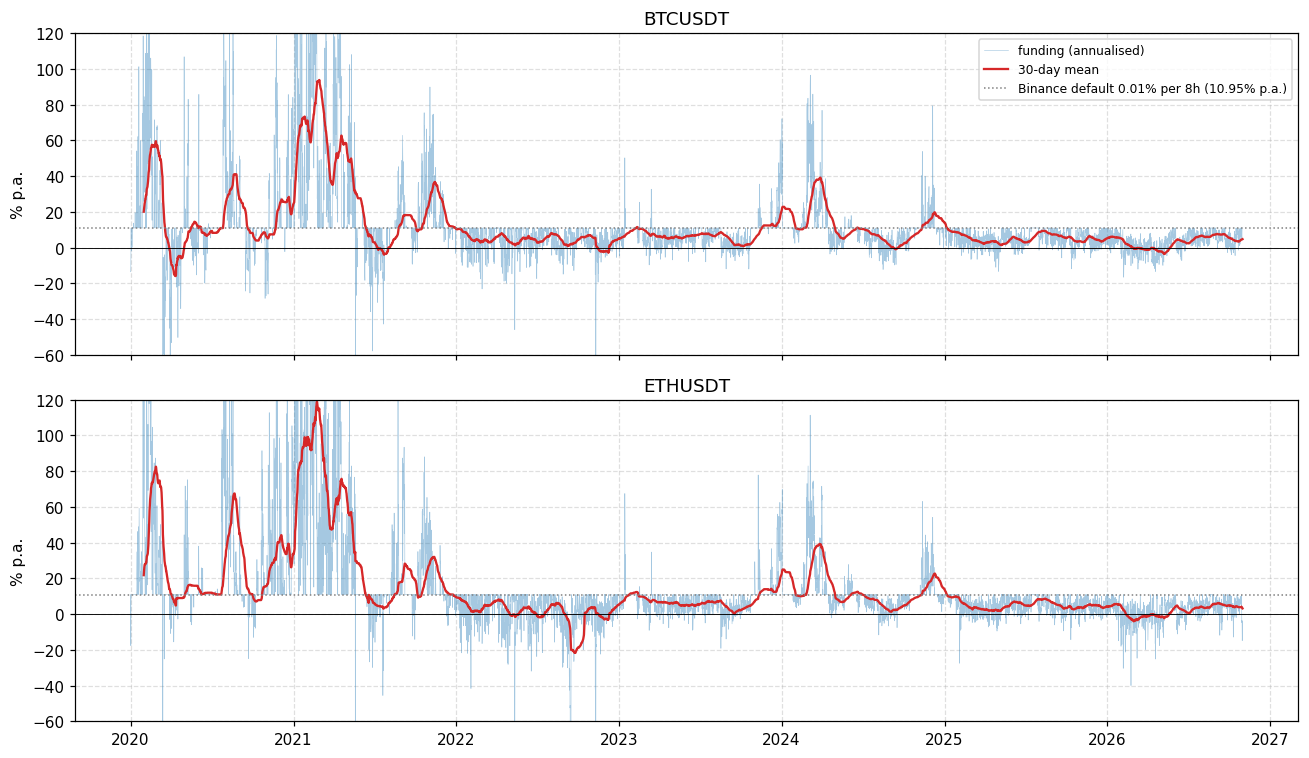

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, s in zip(axes, symbols):
    f = panels[s]["funding"] * cc.PERIODS_PER_YEAR * 100
    ax.plot(f.index, f, lw=0.4, alpha=0.4, label="funding (annualised)")
    ax.plot(f.index, f.rolling(90).mean(), lw=1.5, color="tab:red", label="30-day mean")
    ax.axhline(0, color="black", lw=0.6)
    ax.axhline(10.95, color="grey", ls=":", lw=1, label="Binance default 0.01% per 8h (10.95% p.a.)")
    ax.set_ylim(-60, 120)
    ax.set_ylabel("% p.a.")
    ax.set_title(s)
    ax.grid(True, ls="--", alpha=0.4)
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [4]:
def funding_stats(f):
    return pd.Series({"mean (% p.a.)": 100 * f.mean() * cc.PERIODS_PER_YEAR,
                      "median (% p.a.)": 100 * f.median() * cc.PERIODS_PER_YEAR,
                      "std (% p.a.)": 100 * f.std() * cc.PERIODS_PER_YEAR,
                      "negative (%)": 100 * (f < 0).mean(),
                      "at 0.01% (%)": 100 * np.isclose(f, 0.0001, atol=5e-7).mean(),
                      "max (% per 8h)": 100 * f.max(), "min (% per 8h)": 100 * f.min()})

funding_table = pd.DataFrame({s: funding_stats(panels[s]["funding"]) for s in symbols})
yearly_funding = pd.DataFrame({s: 100 * panels[s]["funding"].groupby(panels[s].index.year).sum() for s in symbols})
display(funding_table)
yearly_funding.rename_axis("year (funding received, %)")

,BTCUSDT,ETHUSDT
mean (% p.a.),11.68,13.73
median (% p.a.),9.798,10.77
std (% p.a.),22.72,29.68
negative (%),13.95,13.83
at 0.01% (%),33.56,33.39
max (% per 8h),0.3,0.375
min (% per 8h),-0.3,-0.3563


,BTCUSDT,ETHUSDT
"year (funding received, %)",,
2020,17.24,27.49
2021,30.68,37.42
2022,4.149,0.7838
2023,7.851,8.239
2024,11.96,13
2025,5.126,4.929
2026,2.581,1.724


The funding is positive on average (the perpetual trades above the spot because longs pay to keep leveraged long positions), but very unequal across the years : about 30% in 2021, a few percent in 2022 and since 2025. A third of the payments are exactly 0.01% per 8 hours (10.95% a year), the interest rate component of the Binance formula when the premium is small ; 14% of them are negative.

### 1.2 Persistence of the funding

A threshold strategy only works if the funding is predictable : autocorrelation of the funding rate at lags of 8 hours to 30 days.

In [5]:
lags = [1, 3, 9, 21, 45, 90]
autocorr = pd.DataFrame({s: [panels[s]["funding"].autocorr(l) for l in lags] for s in symbols},
                        index=pd.Index(["8h", "1 day", "3 days", "1 week", "15 days", "30 days"], name="lag"))
autocorr

,BTCUSDT,ETHUSDT
lag,,
8h,0.7998,0.789
1 day,0.6981,0.6556
3 days,0.6187,0.571
1 week,0.4664,0.4537
15 days,0.3292,0.3872
30 days,0.3264,0.3226


The funding is persistent : the autocorrelation is 0.8 at 8 hours, 0.7 at one day and still 0.3 after a month. The last payments are a good predictor of the next one, which is what the threshold strategies rely on.

### 1.3 Basis

Basis $F/S - 1$ between the perpetual and the spot at the funding times, in basis points.

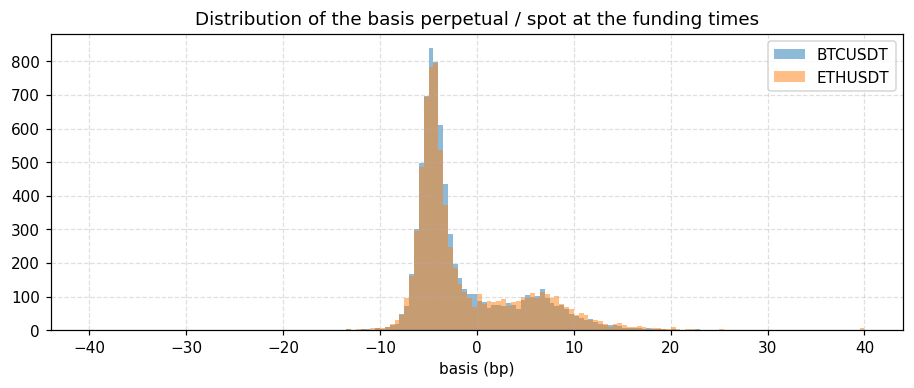

,count,mean,std,min,1%,5%,50%,95%,99%,max
BTCUSDT,7461,-1.574,5.832,-78.6,-8.223,-6.487,-3.832,9.371,14.72,178.7
ETHUSDT,7461,-1.059,6.349,-65.01,-8.454,-6.563,-3.809,10.68,18.55,76.41


In [6]:
basis = pd.DataFrame({s: 1e4 * (panels[s]["perp"] / panels[s]["spot"] - 1) for s in symbols})
fig, ax = plt.subplots(figsize=(10, 3.5))
for s in symbols:
    ax.hist(basis[s].clip(-40, 40), bins=160, alpha=0.5, label=s)
ax.set_xlabel("basis (bp)")
ax.set_title("Distribution of the basis perpetual / spot at the funding times")
ax.legend()
ax.grid(True, ls="--", alpha=0.4)
plt.show()
basis.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T

## 2. Benchmark : always invested

Long spot / short perpetual at all times, on BTC, on ETH, and 50/50.

In [7]:
def run(weights, **kwargs):
    return cc.backtest(panels, weights, **kwargs), weights

signals = {m: pd.concat({s: cc.funding_signal(panels[s], m, window=21) for s in symbols}, axis=1)
           for m in ["last", "mean", "ewm", "premium"]}
strategies = {
    "Always BTC": run(cc.always_invested(signals["last"][["BTCUSDT"]])),
    "Always ETH": run(cc.always_invested(signals["last"][["ETHUSDT"]])),
    "Always 50/50": run(cc.always_invested(signals["last"])),
}
pd.DataFrame({k: cc.performance(r, w) for k, (r, w) in strategies.items()}).T

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),funding (% p.a.),basis (% p.a.),time invested (%),positive periods (%),worst period (%),number of entries,average holding (days)
Always BTC,12.33,1.494,7.815,-2.228,11.67,-0.03434,100,64.65,-1.596,1,2495
Always ETH,14.56,1.66,8.226,-2.005,13.78,-0.1785,100,64.01,-1.002,1,2495
Always 50/50,13.44,1.387,9.129,-1.346,12.73,-0.1064,100,67.79,-1.11,2,1248


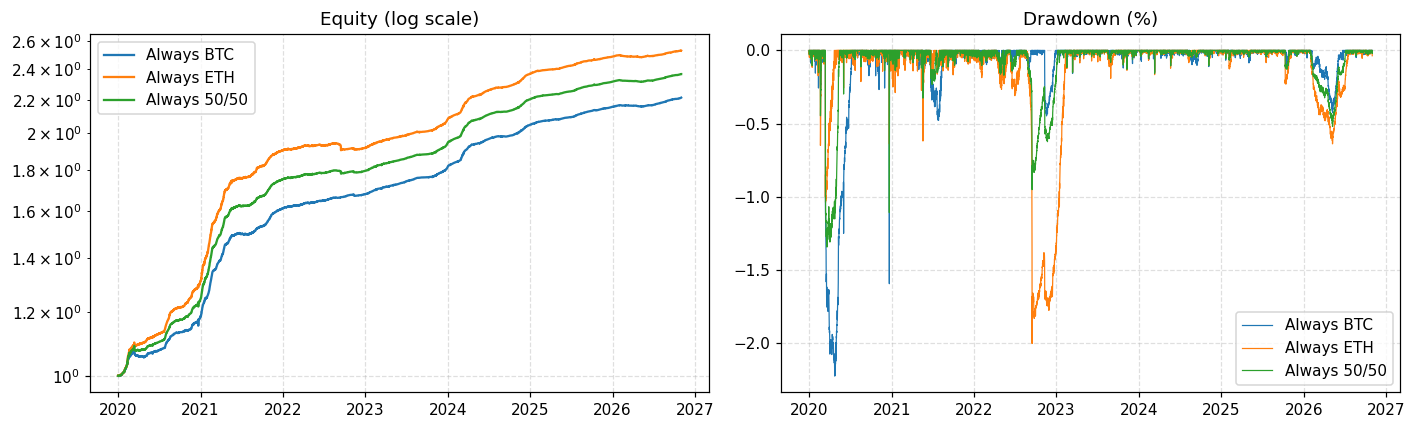

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k in ["Always BTC", "Always ETH", "Always 50/50"]:
    r = strategies[k][0]
    axes[0].plot(r.index, r["equity"], label=k)
    axes[1].plot(r.index, 100 * (r["equity"] / r["equity"].cummax() - 1), label=k, lw=0.8)
axes[0].set_title("Equity (log scale)"); axes[0].set_yscale("log")
axes[1].set_title("Drawdown (%)")
for ax in axes:
    ax.grid(True, ls="--", alpha=0.4); ax.legend()
plt.tight_layout()
plt.show()

In [9]:
pd.concat({k: cc.yearly_returns(strategies[k][0])[["return (%)", "funding (%)", "basis (%)"]] for k in ["Always BTC", "Always ETH"]}, axis=1)

Always BTC                       Always ETH                      
     return (%) funding (%) basis (%) return (%) funding (%) basis (%)
time                                                                  
2020      18.53       17.27   -0.2195      31.15       27.62   -0.4634
2021      36.09       30.81   0.03164      45.28        37.8   -0.4137
2022      4.199       4.158  -0.04208     0.6893      0.8177   -0.1236
2023      8.046       7.866    -0.125      8.444       8.264   -0.1542
2024      12.81       11.99   0.07078      13.89       13.03  -0.01858
2025      5.272       5.122   0.01659      5.059       4.953  -0.01564
2026      2.649       2.583   0.03283      1.735       1.752  -0.03097

The benchmark earns the funding (about 12% a year on BTC, 14% on ETH) with a very low volatility, the basis contributing almost nothing over the whole period since it telescopes : the basis part of a holding period is the basis at the entry minus the basis at the exit. The drawdowns come from the periods of negative funding (March 2020, May 2021, the 2022 bear market) and from the short-term moves of the basis.

## 3. Funding threshold

One position per symbol (half of the capital each), entered when the expected funding is above `entry` (per annum) and kept while it stays above `exit`. Four estimators of the next funding, known at $t_k$ :
- `last` : the funding just paid ;
- `mean` : mean of the last 21 payments (one week) ;
- `ewm` : exponentially weighted mean, half-life of one week ;
- `premium` : Binance formula applied to the premium index at $t_k$.

In [10]:
for m in ["last", "mean", "ewm", "premium"]:
    strategies[f"Threshold {m}"] = run(cc.threshold_positions(signals[m], entry=0.05, exit=0.0))
threshold_table = pd.DataFrame({k: cc.performance(r, w) for k, (r, w) in strategies.items() if k.startswith(("Threshold", "Always 50"))}).T
threshold_table

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),funding (% p.a.),basis (% p.a.),time invested (%),positive periods (%),worst period (%),number of entries,average holding (days)
Always 50/50,13.44,1.387,9.129,-1.346,12.73,-0.1064,100,67.79,-1.11,2,1248
Threshold last,14.33,1.298,10.35,-1.11,12.97,0.4313,88.54,71.57,-1.11,679,3.254
Threshold mean,13.51,1.351,9.422,-1.11,12.71,-0.02077,87.28,70.51,-1.11,39,55.84
Threshold ewm,13.44,1.355,9.346,-1.174,12.68,-0.05821,91.09,69.67,-1.11,15,151.5
Threshold premium,15.77,1.221,12.04,-1.11,12.29,2.366,84.33,77.52,-1.11,1967,1.07


### 3.1 Choice of the threshold

Sweep of the entry threshold (exit at 0, i.e. leave when the expected funding becomes negative), for the `mean` estimator.

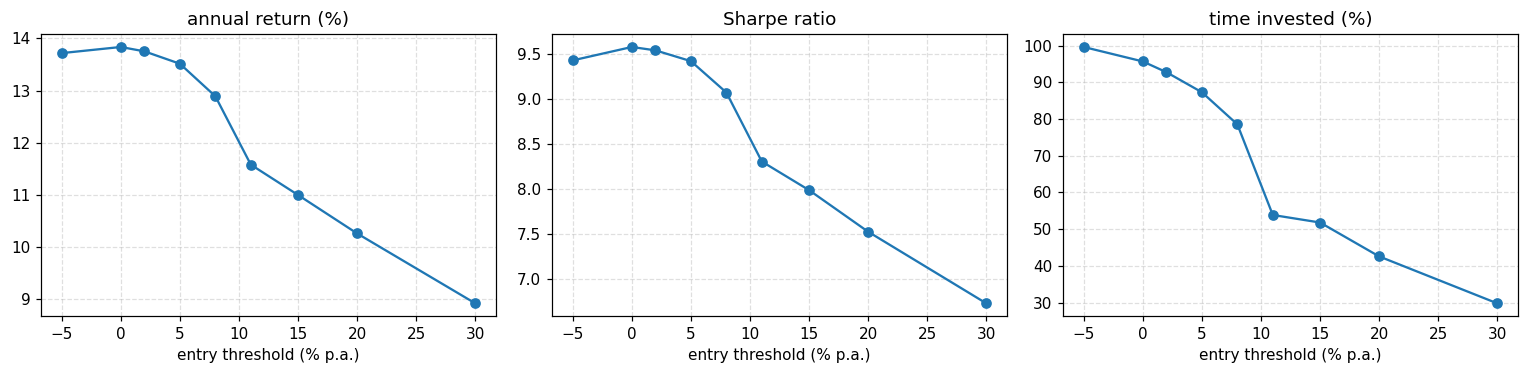

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),time invested (%),number of entries
entry (p.a.),,,,,,
-0.05,13.72,1.369,9.431,-1.11,99.61,30
0,13.84,1.359,9.58,-1.11,95.67,72
0.02,13.75,1.356,9.543,-1.11,92.73,50
0.05,13.51,1.351,9.422,-1.11,87.28,39
0.08,12.89,1.342,9.074,-1.11,78.53,28
0.11,11.58,1.325,8.306,-1.11,53.85,15
0.15,10.99,1.312,7.988,-1.11,51.8,12
0.2,10.26,1.303,7.525,-1.11,42.56,11
0.3,8.914,1.275,6.728,-1.11,29.77,9


In [11]:
entries = [-0.05, 0.0, 0.02, 0.05, 0.08, 0.11, 0.15, 0.20, 0.30]
sweep = pd.DataFrame({e: cc.performance(*run(cc.threshold_positions(signals["mean"], entry=e, exit=min(e, 0.0)))) for e in entries}).T.rename_axis("entry (p.a.)")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["annual return (%)", "Sharpe ratio", "time invested (%)"]):
    ax.plot(100 * sweep.index, sweep[col], "o-")
    ax.set_xlabel("entry threshold (% p.a.)"); ax.set_title(col); ax.grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()
sweep[["annual return (%)", "annual volatility (%)", "Sharpe ratio", "max drawdown (%)", "time invested (%)", "number of entries"]]

The best thresholds are low (0 to 2% a year) : leaving the market only pays when the expected funding is negative. Higher thresholds leave the market too often and lose more positive funding than the negative periods they avoid, so both the return and the Sharpe ratio decrease. Even at its best, the threshold strategy only adds 0.4 point a year to the benchmark (13.84% against 13.44%) : the negative funding periods are short and their cost is small compared to the funding of the rest of the time.

## 4. Dynamic allocation between BTC and ETH

At each period, all the capital goes to the symbol with the highest expected funding among those above the threshold (`mode='best'`, with a switching margin of 2% p.a. to avoid going back and forth), or is split between them (`mode='equal'`). The capital stays in cash when no symbol is eligible.

In [12]:
for m in ["last", "mean", "ewm", "premium"]:
    strategies[f"Dynamic {m}"] = run(cc.dynamic_allocation(signals[m], entry=0.05, exit=0.0, mode="best", switch=0.02))
strategies["Dynamic mean equal"] = run(cc.dynamic_allocation(signals["mean"], entry=0.05, exit=0.0, mode="equal"))
dynamic_table = pd.DataFrame({k: cc.performance(r, w) for k, (r, w) in strategies.items() if k.startswith(("Dynamic", "Always 50"))}).T
dynamic_table

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),funding (% p.a.),basis (% p.a.),time invested (%),positive periods (%),worst period (%),number of entries,average holding (days)
Always 50/50,13.44,1.387,9.129,-1.346,12.73,-0.1064,100,67.79,-1.11,2,1248
Dynamic last,17.96,1.677,9.894,-1.002,14.81,1.719,87.56,70.21,-1.002,1178,1.855
Dynamic mean,15.14,1.554,9.116,-1.039,14.16,-0.04382,85.87,67.12,-1.002,69,31.05
Dynamic ewm,15.02,1.571,8.947,-1.039,14.21,-0.2004,89.93,66.27,-1.002,23,97.57
Dynamic premium,21.97,1.621,12.3,-0.65,13.87,5.999,83.12,77.34,-0.6235,2022,1.026
Dynamic mean equal,13.92,1.38,9.48,-1.172,13.08,-0.03525,87.28,70.51,-1.11,61,35.7


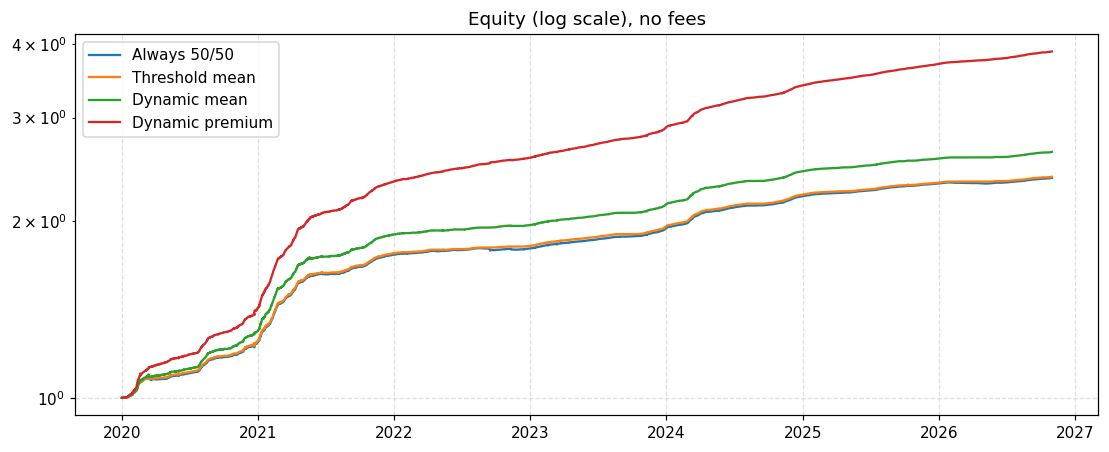

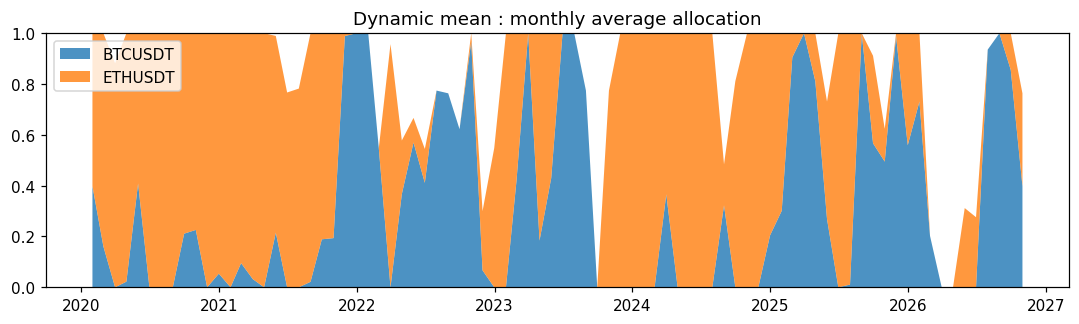

In [13]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for k in ["Always 50/50", "Threshold mean", "Dynamic mean", "Dynamic premium"]:
    r = strategies[k][0]
    ax.plot(r.index, r["equity"], label=k)
ax.set_yscale("log"); ax.set_title("Equity (log scale), no fees")
ax.grid(True, ls="--", alpha=0.4); ax.legend()
plt.show()

w = strategies["Dynamic mean"][1]
allocation = w.resample("ME").mean()
fig, ax = plt.subplots(figsize=(12, 3))
ax.stackplot(allocation.index, allocation.T, labels=allocation.columns, alpha=0.8)
ax.set_title("Dynamic mean : monthly average allocation"); ax.set_ylim(0, 1); ax.legend(loc="upper left")
plt.show()

The dynamic allocation on the one-week mean holds ETH 53% of the time, BTC 33% and cash 14%, and follows the funding : 87% ETH in 2020 and 2024, mostly BTC in 2022 and 2025. It earns 15.1% a year, 1.7 point more than the 50/50 benchmark but only 0.6 point more than the always invested ETH position, which had the highest funding over the period.

The `last` and `premium` signals trade almost every day and earn a large basis gain (1.7% and 6.0% a year) : they enter when the perpetual is expensive relative to the spot and leave when it is cheap, so the basis converges in their favour. This gain is real in the data, but it is made of a few basis points per trade and does not survive trading fees (section 6).

## 5. Risk

### 5.1 Decomposition and worst periods

In [14]:
key = ["Always 50/50", "Threshold mean", "Dynamic mean", "Dynamic premium"]
pd.DataFrame({k: cc.yearly_returns(strategies[k][0])["return (%)"] for k in key})

,Always 50/50,Threshold mean,Dynamic mean,Dynamic premium
time,,,,
2020,24.69,25.29,30.36,42.53
2021,40.62,40.68,45.52,63.89
2022,2.431,2.945,3.78,9.731
2023,8.246,7.934,8.467,12.69
2024,13.35,13.23,13.8,17.8
2025,5.166,4.839,5.147,8.797
2026,2.192,2.322,2.629,4.997


In [15]:
r = strategies["Dynamic mean"][0]
worst = r["return"].nsmallest(5)
pd.DataFrame({"return (%)": 100 * worst, "funding (%)": 100 * r.loc[worst.index, "funding"], "basis (%)": 100 * r.loc[worst.index, "basis"]})

,return (%),funding (%),basis (%)
time,,,
2020-03-13 08:00:00+00:00,-1.002,-0.3329,-0.6687
2020-12-21 16:00:00+00:00,-0.6235,0.01668,-0.6402
2021-05-19 16:00:00+00:00,-0.6198,-0.3283,-0.2915
2020-02-20 00:00:00+00:00,-0.5292,0.01789,-0.5471
2020-06-02 00:00:00+00:00,-0.2575,0.03632,-0.2938


### 5.2 Margin

Cross / portfolio margin : the spot is the collateral of the short perpetual, valued with a haircut of 5%, and the maintenance margin of the perpetual is 0.4% of the notional. The quantity is fixed at the entry of each holding period, so a rise of the index creates an unrealised loss on the perpetual that is only covered by the spot. The ratio equity / maintenance must stay above 1.

In [16]:
margin = {}
for k in ["Always BTC", "Always ETH", "Dynamic mean"]:
    r, w = strategies[k]
    for s in w.columns:
        if (w[s] > 0).any():
            ratio, rise = cc.margin_ratio(panels[s], w[s])
            margin[f"{k} ({s})"] = {"minimum ratio": ratio.min(), "date": ratio.idxmin().strftime("%Y-%m-%d"),
                                    "liquidation if the index is multiplied by": rise}
pd.DataFrame(margin).T

,minimum ratio,date,liquidation if the index is multiplied by
Always BTC (BTCUSDT),50.28,2021-01-08,18.52
Always ETH (ETHUSDT),29.46,2021-05-12,18.52
Dynamic mean (BTCUSDT),168.4,2026-09-22,18.52
Dynamic mean (ETHUSDT),93,2021-05-12,18.52


With the spot as collateral, the position is only liquidated if the index is multiplied by about 18 since the entry of the holding period : even the benchmark held from January 2020 (BTC multiplied by 17 at the 2025 high) stays far above the maintenance margin thanks to the accumulated funding. The risk of this setup is not the liquidation, but the counterparty risk of the exchange that holds both legs.

## 6. Trading fees

Sensitivity of the strategies to proportional fees paid on each leg at each change of position (Binance VIP 0 : 0.10% spot taker, 0.05% perpetual taker ; maker fees are lower).

In [17]:
fee_levels = [0.0, 0.0001, 0.0002, 0.0005, 0.001]
fee_table = pd.DataFrame({k: [cc.performance(cc.backtest(panels, strategies[k][1], fees=(fee, fee)), strategies[k][1])["annual return (%)"] for fee in fee_levels]
                          for k in ["Always 50/50", "Threshold mean", "Threshold ewm", "Dynamic mean", "Dynamic ewm", "Dynamic last", "Dynamic premium"]},
                         index=pd.Index([f"{1e4 * f:g} bp" for f in fee_levels], name="fee per leg")).T
fee_table

fee per leg,0 bp,1 bp,2 bp,5 bp,10 bp
Always 50/50,13.44,13.44,13.43,13.42,13.41
Threshold mean,13.51,13.39,13.26,12.89,12.26
Threshold ewm,13.44,13.39,13.34,13.2,12.97
Dynamic mean,15.14,14.68,14.23,12.86,10.61
Dynamic ewm,15.02,14.87,14.72,14.27,13.51
Dynamic last,17.96,10.11,2.773,-16.43,-40.84
Dynamic premium,21.97,8.362,-3.728,-32.51,-62.69


The strategies that trade every day (signals `last` and `premium`) lose everything with a few basis points of fees : 2 bp per leg are enough to wipe out the `last` signal. The strategies on smoothed signals trade a few dozen times in six years and lose 0.2 to 2 points a year at 5 bp per leg. With fees, the dynamic allocation on the exponential mean (14.27% at 5 bp) still beats the 50/50 benchmark (13.42%), but not the always invested ETH position (14.54%).

## 7. Out-of-sample test

The threshold and the estimator are chosen on 2020-2022, then the strategy is run on 2023-2026, with fees of 5 bp per leg.

In [18]:
split = pd.Timestamp("2023-01-01", tz="UTC")

def perf_between(result, weights, start=None, end=None):
    sub = result.loc[start:end].copy()
    sub["equity"] = (1 + sub["return"]).cumprod()
    return cc.performance(sub, weights.loc[start:end])

grid = {}
for m in ["mean", "ewm"]:
    for e in [0.0, 0.02, 0.05, 0.08, 0.11, 0.15]:
        w = cc.dynamic_allocation(signals[m], entry=e, exit=min(e, 0.0), mode="best", switch=0.02)
        res = cc.backtest(panels, w, fees=(0.0005, 0.0005))
        grid[(m, e)] = {"in-sample Sharpe": perf_between(res, w, end=split)["Sharpe ratio"],
                        "in-sample return (%)": perf_between(res, w, end=split)["annual return (%)"],
                        "out-of-sample Sharpe": perf_between(res, w, start=split)["Sharpe ratio"],
                        "out-of-sample return (%)": perf_between(res, w, start=split)["annual return (%)"]}
grid = pd.DataFrame(grid).T.rename_axis(["signal", "entry"])
best = grid["in-sample Sharpe"].idxmax()
print("chosen on 2020-2022 (5 bp fees per leg) :", best)
grid

chosen on 2020-2022 (5 bp fees per leg) : ('ewm', np.float64(0.02))


in-sample Sharpe  in-sample return (%)  out-of-sample Sharpe  out-of-sample return (%)
signal entry                                                                                        
mean   0                 8.558                 21.95                 6.376                     5.716
       0.02              8.588                 21.98                 7.361                     6.246
       0.05              8.637                 21.97                 7.626                       6.2
       0.08              8.794                 22.04                 8.623                     6.263
       0.11              8.753                 21.16                 8.326                      4.97
       0.15              8.748                 21.05                 7.957                     4.746
ewm    0                 9.702                 24.47                 9.167                     6.948
       0.02              9.703                 24.45                 9.563                     7.067
       0.05              9.612                 24.11                 10.17                     7.102
       0.08              9.548                 23.75                 10.33                     6.946
       0.11              9.589                 23.75                 10.36                     6.802
       0.15              9.374                 23.12                 9.631                     5.319

In [19]:
bench = cc.backtest(panels, strategies["Always 50/50"][1], fees=(0.0005, 0.0005))
w_best = cc.dynamic_allocation(signals[best[0]], entry=best[1], exit=min(best[1], 0.0), mode="best", switch=0.02)
res_best = cc.backtest(panels, w_best, fees=(0.0005, 0.0005))
pd.DataFrame({"Always 50/50 (out-of-sample)": perf_between(bench, strategies["Always 50/50"][1], start=split),
              f"Dynamic {best[0]} {best[1]:.0%} (out-of-sample)": perf_between(res_best, w_best, start=split)}).T

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),funding (% p.a.),basis (% p.a.),time invested (%),positive periods (%),worst period (%),number of entries,average holding (days)
Always 50/50 (out-of-sample),7.479,0.5648,12.8,-0.5205,7.244,-0.02923,100,68.72,-0.1568,2,699.8
Dynamic ewm 2% (out-of-sample),7.067,0.7157,9.563,-0.4715,7.563,-0.001099,92.6,66.99,-0.2096,15,86.41


**Out-of-sample.** The parameters chosen on 2020-2022 (exponential mean, entry at 2%) earn 7.07% a year on 2023-2026, against 7.48% for the 50/50 benchmark and 7.51% for the always invested ETH position : the timing does not add value out of sample. Its Sharpe ratio is lower too (9.6 against 12.8), since the switches between BTC and ETH add the noise of the basis without enough additional funding. On this period, the funding was low and stable, and staying invested was the best choice.

## 8. Summary

In [20]:
summary_keys = ["Always BTC", "Always ETH", "Always 50/50", "Threshold mean", "Threshold ewm", "Dynamic mean", "Dynamic ewm", "Dynamic last", "Dynamic premium"]
summary = pd.DataFrame({k: cc.performance(*strategies[k]) for k in summary_keys}).T
summary["return with 5 bp fees (%)"] = [cc.performance(cc.backtest(panels, strategies[k][1], fees=(0.0005, 0.0005)), strategies[k][1])["annual return (%)"] for k in summary_keys]
summary[["annual return (%)", "annual volatility (%)", "Sharpe ratio", "max drawdown (%)", "funding (% p.a.)", "basis (% p.a.)",
         "time invested (%)", "number of entries", "return with 5 bp fees (%)"]]

,annual return (%),annual volatility (%),Sharpe ratio,max drawdown (%),funding (% p.a.),basis (% p.a.),time invested (%),number of entries,return with 5 bp fees (%)
Always BTC,12.33,1.494,7.815,-2.228,11.67,-0.03434,100,1,12.31
Always ETH,14.56,1.66,8.226,-2.005,13.78,-0.1785,100,1,14.54
Always 50/50,13.44,1.387,9.129,-1.346,12.73,-0.1064,100,2,13.42
Threshold mean,13.51,1.351,9.422,-1.11,12.71,-0.02077,87.28,39,12.89
Threshold ewm,13.44,1.355,9.346,-1.174,12.68,-0.05821,91.09,15,13.2
Dynamic mean,15.14,1.554,9.116,-1.039,14.16,-0.04382,85.87,69,12.86
Dynamic ewm,15.02,1.571,8.947,-1.039,14.21,-0.2004,89.93,23,14.27
Dynamic last,17.96,1.677,9.894,-1.002,14.81,1.719,87.56,1178,-16.43
Dynamic premium,21.97,1.621,12.3,-0.65,13.87,5.999,83.12,2022,-32.51


**Conclusions**
- The benchmark earns the funding, 12% a year on BTC and 14% on ETH since 2020, with a volatility below 2% and a maximum drawdown of 1 to 2%. Most of it comes from 2020-2021 and 2024 ; the yield has fallen to a few percent since 2025.
- The funding is persistent, but its negative periods are short and cheap : a threshold on the expected funding only adds a few tenths of a point a year, and the best threshold is close to zero.
- The dynamic allocation between BTC and ETH adds 1.7 point a year to the 50/50 benchmark in sample, but it does not beat the always invested ETH position, and it underperforms the benchmark out of sample (7.07% against 7.48% on 2023-2026).
- The fast signals earn a large basis gain without fees, which disappears with 2 bp per leg.
- With the spot as collateral, the liquidation risk is negligible (an 18-fold rise of the index would be needed). The remaining risks are the exchange holding both legs, the regimes of low or negative funding, and the yield of the capital, not modelled here : with a risk-free rate of 4 to 5% in USD since 2023, the excess return of the carry is small.